# Tugas Praktikum #4 — Asyncio (Pertemuan 7)

**Mata Kuliah:** Pemrosesan Paralel dengan Python  
Nama / NIM:Rhadid Asja Putra Danisa/2311513030



---
## 1️⃣ Eksperimen Skala: `daftar_paket_banyak` dan `BATAS_KONKURENSI`

**Rencana:** daftar paket diperbesar menjadi 25 paket PyPI populer. Untuk setiap `BATAS_KONKURENSI` ∈ {1, 3, 5, 10, 20}, waktu total pengambilan metadata diukur memakai `asyncio.Semaphore` (pola yang sama dengan bagian 6.3). Setiap konfigurasi diulang 5 kali (urutannya diselang-seling) dan diambil **median**-nya, supaya hasil tidak terlalu dipengaruhi fluktuasi jaringan sesaat.

In [1]:
import aiohttp
import asyncio
import time
import statistics

# 25 paket PyPI populer
daftar_paket_banyak = [
    "requests", "numpy", "flask", "aiohttp", "pandas", "django",
    "scipy", "matplotlib", "pillow", "sqlalchemy", "pytest", "beautifulsoup4",
    "lxml", "fastapi", "pydantic", "scikit-learn", "boto3", "urllib3",
    "certifi", "click", "jinja2", "pyyaml", "cryptography", "tqdm", "openpyxl",
]
print("Jumlah paket:", len(daftar_paket_banyak), "| unik:", len(set(daftar_paket_banyak)))

async def ambil_metadata_paket(session, nama_paket):
    url = f"https://pypi.org/pypi/{nama_paket}/json"
    async with session.get(url) as response:
        data = await response.json()
        info = data["info"]
        return {
            "nama": info["name"],
            "versi": info["version"],
            "summary": (info["summary"] or "")[:60],
        }

async def ambil_dengan_batas(session, nama_paket, semaphore):
    async with semaphore:  # hanya N coroutine yang boleh masuk blok ini bersamaan
        return await ambil_metadata_paket(session, nama_paket)

async def ukur_waktu(batas):
    semaphore = asyncio.Semaphore(batas)
    start = time.perf_counter()
    async with aiohttp.ClientSession() as session:
        hasil = await asyncio.gather(
            *[ambil_dengan_batas(session, p, semaphore) for p in daftar_paket_banyak]
        )
    return time.perf_counter() - start, hasil

Jumlah paket: 25 | unik: 25


**Validasi:** sebelum diukur, semua 25 nama paket harus benar-benar valid di PyPI (satu kali pemanggilan pemanasan, sekaligus menghangatkan cache DNS/CDN agar tidak mengganggu pengukuran pertama).

In [2]:
waktu_pemanasan, hasil_pemanasan = await ukur_waktu(20)
print(f"Pemanasan selesai: {len(hasil_pemanasan)} paket berhasil diambil ({waktu_pemanasan:.2f} detik)\n")
for h in hasil_pemanasan[:5]:
    print(f"  {h['nama']:<15} v{h['versi']:<10} {h['summary']}")
print("  ...")

Pemanasan selesai: 25 paket berhasil diambil (0.71 detik)

  requests        v2.34.2     Python HTTP for Humans.
  numpy           v2.5.4      Fundamental package for array computing in Python
  Flask           v3.1.3      A simple framework for building complex web applications.
  aiohttp         v3.14.5     Async http client/server framework (asyncio)
  pandas          v3.0.6      Powerful data structures for data analysis, time series, and
  ...


In [3]:
BATAS_UJI = [1, 3, 5, 10, 20]
ULANGAN = 5
catatan = {b: [] for b in BATAS_UJI}

for u in range(ULANGAN):
    for b in BATAS_UJI:            # diselang-seling agar drift jaringan merata
        t, hasil = await ukur_waktu(b)
        assert len(hasil) == len(daftar_paket_banyak)
        catatan[b].append(t)

median_waktu = {b: statistics.median(v) for b, v in catatan.items()}
print(f"{'Batas':>5} | {'Median (s)':>10} | {'Min (s)':>8} | {'Maks (s)':>8}")
print("-" * 42)
for b in BATAS_UJI:
    print(f"{b:>5} | {median_waktu[b]:>10.3f} | {min(catatan[b]):>8.3f} | {max(catatan[b]):>8.3f}")

Batas | Median (s) |  Min (s) | Maks (s)
------------------------------------------
    1 |      0.909 |    0.819 |    1.043
    3 |      0.464 |    0.425 |    0.766
    5 |      0.478 |    0.451 |    1.022
   10 |      0.505 |    0.439 |    0.572
   20 |      0.428 |    0.410 |    0.550


### Plot waktu vs batas konkurensi

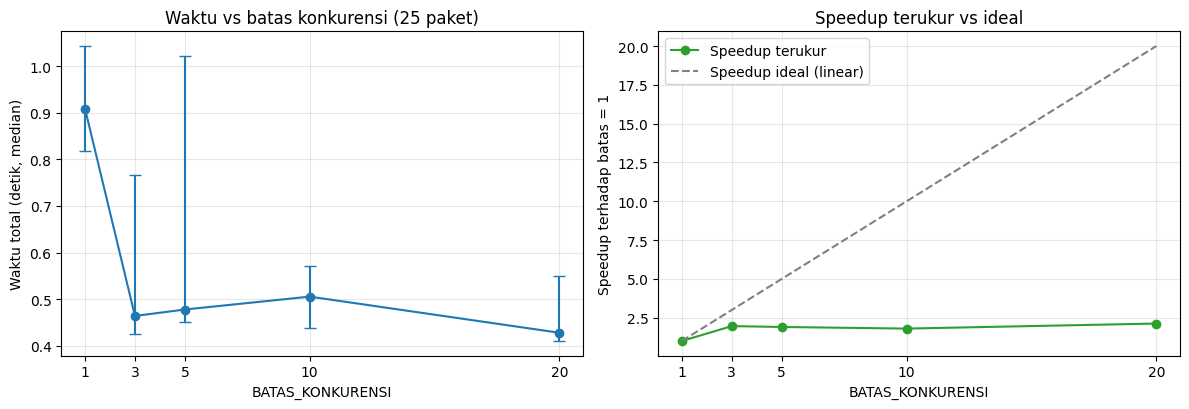

In [4]:
import matplotlib.pyplot as plt

xs = BATAS_UJI
ys = [median_waktu[b] for b in xs]
err_bawah = [median_waktu[b] - min(catatan[b]) for b in xs]
err_atas = [max(catatan[b]) - median_waktu[b] for b in xs]

speedup = [median_waktu[1] / median_waktu[b] for b in xs]
ideal = [min(b, len(daftar_paket_banyak)) for b in xs]

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))

ax[0].errorbar(xs, ys, yerr=[err_bawah, err_atas], fmt="o-", capsize=4, color="tab:blue")
ax[0].set_xticks(xs)
ax[0].set_xlabel("BATAS_KONKURENSI")
ax[0].set_ylabel("Waktu total (detik, median)")
ax[0].set_title(f"Waktu vs batas konkurensi ({len(daftar_paket_banyak)} paket)")
ax[0].grid(alpha=0.3)

ax[1].plot(xs, speedup, "o-", label="Speedup terukur", color="tab:green")
ax[1].plot(xs, ideal, "--", label="Speedup ideal (linear)", color="gray")
ax[1].set_xticks(xs)
ax[1].set_xlabel("BATAS_KONKURENSI")
ax[1].set_ylabel("Speedup terhadap batas = 1")
ax[1].set_title("Speedup terukur vs ideal")
ax[1].legend()
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Analisis: kapan tambahan konkurensi mulai tidak berarti?

In [5]:
print(f"{'Batas':>5} | {'Waktu (s)':>9} | {'Speedup':>7} | {'Ideal':>5} | {'Efisiensi':>9} | {'Turun vs sebelumnya':>20}")
print("-" * 72)
sebelumnya = None
titik_kecil = None
for b in BATAS_UJI:
    t = median_waktu[b]
    s = median_waktu[1] / t
    efisiensi = s / min(b, len(daftar_paket_banyak)) * 100
    if sebelumnya is None:
        turun = "-"
    else:
        persen = (sebelumnya - t) / sebelumnya * 100
        turun = f"{persen:5.1f}%"
        if titik_kecil is None and persen < 10:
            titik_kecil = b
    print(f"{b:>5} | {t:>9.3f} | {s:>6.2f}x | {min(b, 25):>5} | {efisiensi:>8.1f}% | {turun:>20}")
    sebelumnya = t

print()
if titik_kecil:
    print(f"Penambahan batas pertama kali memberi penurunan waktu < 10% pada BATAS_KONKURENSI = {titik_kecil}")
else:
    print("Pada rentang ini, setiap penambahan batas masih memberi penurunan waktu >= 10%.")

# Perbandingan dengan Hukum Amdahl: S(N) = 1 / ((1 - P) + P / N)
N_maks = BATAS_UJI[-1]
S_maks = median_waktu[1] / median_waktu[N_maks]
P = (1 - 1 / S_maks) / (1 - 1 / N_maks)
print(f"\nEstimasi bagian yang bisa diparalelkan (P) dari data batas = {N_maks}: {P:.2f}")
print(f"{'N':>3} | {'Speedup terukur':>15} | {'Prediksi Amdahl':>15}")
for b in BATAS_UJI:
    amdahl = 1 / ((1 - P) + P / b)
    print(f"{b:>3} | {median_waktu[1]/median_waktu[b]:>14.2f}x | {amdahl:>14.2f}x")

Batas | Waktu (s) | Speedup | Ideal | Efisiensi |  Turun vs sebelumnya
------------------------------------------------------------------------
    1 |     0.909 |   1.00x |     1 |    100.0% |                    -
    3 |     0.464 |   1.96x |     3 |     65.3% |                48.9%
    5 |     0.478 |   1.90x |     5 |     38.0% |                -3.0%
   10 |     0.505 |   1.80x |    10 |     18.0% |                -5.8%
   20 |     0.428 |   2.12x |    20 |     10.6% |                15.3%

Penambahan batas pertama kali memberi penurunan waktu < 10% pada BATAS_KONKURENSI = 5

Estimasi bagian yang bisa diparalelkan (P) dari data batas = 20: 0.56
  N | Speedup terukur | Prediksi Amdahl
  1 |           1.00x |           1.00x
  3 |           1.96x |           1.59x
  5 |           1.90x |           1.80x
 10 |           1.80x |           2.00x
 20 |           2.12x |           2.12x


**Pengamatan (dari eksekusi di atas):**

- **Batas 1 → 3:** waktu turun dari ≈ 0,91 s menjadi ≈ 0,46 s (turun ≈ 49%, speedup ≈ 1,96×). Ini satu-satunya lompatan besar.
- **Batas 3 → 5 → 10 → 20:** waktu bertahan di kisaran 0,43–0,51 s. Selisihnya (bahkan sempat "naik" 3% dan 6%) lebih kecil daripada variasi antar-ulangan pada kolom Min–Maks, sehingga tidak bisa dibedakan dari fluktuasi jaringan.
- **Jawaban:** penambahan batas konkurensi mulai memberi manfaat **sangat kecil setelah sekitar `BATAS_KONKURENSI = 3`**. Program mendeteksi penurunan waktu < 10% untuk pertama kali pada langkah 3 → 5. Efisiensi (speedup ÷ speedup ideal) merosot dari 65% (N = 3) ke 38% (N = 5) dan hanya ≈ 11% (N = 20).

**Kaitan dengan Hukum Amdahl (Pertemuan 1):** speedup maksimum dibatasi bagian program yang tidak bisa diparalelkan, S(N) = 1 / ((1 − P) + P / N). Dari data N = 20 diperoleh estimasi P ≈ 0,56. Artinya hanya sekitar 56% waktu total yang benar-benar menyusut ketika konkurensi dinaikkan (waktu menunggu respons jaringan). Sisanya ≈ 44% adalah bagian "tetap" yang tidak ikut menyusut, misalnya pembuatan `ClientSession`, resolusi DNS dan pembukaan koneksi, parsing JSON, dan overhead event loop. Batas atas speedup menjadi 1 / (1 − P) ≈ 2,3×, dan speedup terukur memang mentok di sekitar 2× berapa pun N dinaikkan. Itulah *diminishing returns*: setelah bagian yang bisa diparalelkan "habis" dibagi, menambah N hanya mengecilkan bagian yang sudah kecil.

**Alasan tambahan yang mendukung:**

- Dengan 25 paket dan batas 20, request hanya berjalan dalam ⌈25/20⌉ = 2 "gelombang". Dari batas 10 ke 20 jumlah gelombang hanya turun dari 3 ke 2, jadi memang tidak banyak yang bisa dihemat lagi.
- Latensi PyPI kecil (≈ 36 ms per request saat berurutan, yaitu 0,91 s ÷ 25), sehingga waktu tunggu yang bisa dihemat sejak awal tidak besar dibanding bagian tetapnya.
- Dugaan saya (tidak diukur terpisah): semakin besar batas, semakin banyak koneksi baru yang harus dibuka, dan setiap koneksi baru membawa biaya handshake sendiri. Ini ikut menahan penurunan waktu.
- Batas besar juga tidak gratis: lebih banyak request bersamaan membebani server tujuan dan menaikkan risiko terkena *rate limit*. Untuk skala 25 paket, batas sekitar 3–5 adalah pilihan yang masuk akal.

*Catatan:* karena ini request jaringan nyata, angka persisnya bisa berbeda tiap kali dijalankan, dan estimasi P berasal dari satu titik data yang berisik (sebab itu prediksi Amdahl di tabel tidak persis sama dengan hasil ukur, misalnya N = 3). Pola umumnya, yaitu lonjakan di awal lalu mendatar, adalah yang penting.

---
## 2️⃣ Deteksi Blocking Call

**Rencana:** tiga coroutine dibuat dengan perilaku berbeda, masing-masing dengan "durasi kerja" yang sebanding supaya perbandingannya adil:

| Coroutine | Isi | Mengandung `await`? |
|---|---|---|
| `tugas_async_sleep` | `await asyncio.sleep(0.5)` | Ya (non-blocking) |
| `tugas_time_sleep` | `time.sleep(0.5)` | Tidak (blocking) |
| `tugas_cpu_bound` | hitung faktorial angka besar dalam loop | Tidak sama sekali (CPU-bound) |

Sebagai **pengukur**, ada coroutine `pengukur` yang hanya mengulang `await asyncio.sleep(0.1)` dan mencatat waktu setiap "detak". Jika event loop sehat, jarak antar detak ≈ 0,1 detik. Jika ada coroutine yang memblokir event loop, jarak antar detak akan **melonjak** — itulah cara mendeteksinya.

In [6]:
import asyncio
import time

def faktorial_loop(n):
    """CPU-bound murni: perkalian bertubi-tubi, tanpa await sama sekali."""
    hasil = 1
    for i in range(2, n + 1):
        hasil *= i
    return hasil

N_FAKTORIAL = 60000

async def tugas_async_sleep(selesai, durasi=0.5):
    await asyncio.sleep(durasi)          # non-blocking: menyerahkan giliran
    selesai.append("async_sleep")

async def tugas_time_sleep(selesai, durasi=0.5):
    time.sleep(durasi)                   # BLOCKING: event loop macet
    selesai.append("time_sleep")

async def tugas_cpu_bound(selesai, n=N_FAKTORIAL):
    faktorial_loop(n)                    # CPU-bound: tidak ada titik await
    selesai.append("cpu_bound")

async def pengukur(selesai, jumlah_tugas, interval=0.1):
    """Mencatat waktu setiap detak; berhenti setelah semua tugas selesai."""
    detak = [time.perf_counter()]
    while len(selesai) < jumlah_tugas:
        await asyncio.sleep(interval)
        detak.append(time.perf_counter())
    return [b - a for a, b in zip(detak, detak[1:])]   # jarak antar detak

def laporan(nama, total, jarak):
    maks = max(jarak) if jarak else 0
    print(f"{nama:<28} total={total:5.2f}s | jumlah detak={len(jarak)+1:>2} | "
          f"jarak detak terbesar={maks:5.2f}s (ideal 0.10s)")

### 2a. Setiap coroutine dijalankan sendiri bersama pengukur (untuk melihat siapa pelakunya)

In [7]:
async def uji_tunggal(nama, fungsi_tugas):
    selesai = []
    start = time.perf_counter()
    jarak, _ = await asyncio.gather(pengukur(selesai, 1), fungsi_tugas(selesai))
    laporan(nama, time.perf_counter() - start, jarak)
    return jarak

jarak_async = await uji_tunggal("asyncio.sleep(0.5)", tugas_async_sleep)
jarak_time  = await uji_tunggal("time.sleep(0.5)", tugas_time_sleep)
jarak_cpu   = await uji_tunggal(f"faktorial({N_FAKTORIAL}) CPU-bound", tugas_cpu_bound)

asyncio.sleep(0.5)           total= 0.50s | jumlah detak= 6 | jarak detak terbesar= 0.10s (ideal 0.10s)


time.sleep(0.5)              total= 0.50s | jumlah detak= 2 | jarak detak terbesar= 0.50s (ideal 0.10s)


faktorial(60000) CPU-bound   total= 0.76s | jumlah detak= 2 | jarak detak terbesar= 0.76s (ideal 0.10s)


### 2b. Ketiganya sekaligus dengan `asyncio.gather()` + satu coroutine pengukur

In [8]:
selesai = []
start = time.perf_counter()
hasil_gabungan = await asyncio.gather(
    pengukur(selesai, 3),                 # pengukur (memakai asyncio.sleep)
    tugas_async_sleep(selesai),
    tugas_time_sleep(selesai),
    tugas_cpu_bound(selesai),
)
total_gabungan = time.perf_counter() - start
jarak_gabungan = hasil_gabungan[0]

laporan("Ketiganya + pengukur", total_gabungan, jarak_gabungan)
print("\nUrutan selesai:", selesai)
print("Jarak antar detak pengukur (detik):", [round(j, 2) for j in jarak_gabungan])

Ketiganya + pengukur         total= 1.42s | jumlah detak= 3 | jarak detak terbesar= 1.32s (ideal 0.10s)

Urutan selesai: ['time_sleep', 'cpu_bound', 'async_sleep']
Jarak antar detak pengukur (detik): [1.32, 0.1]


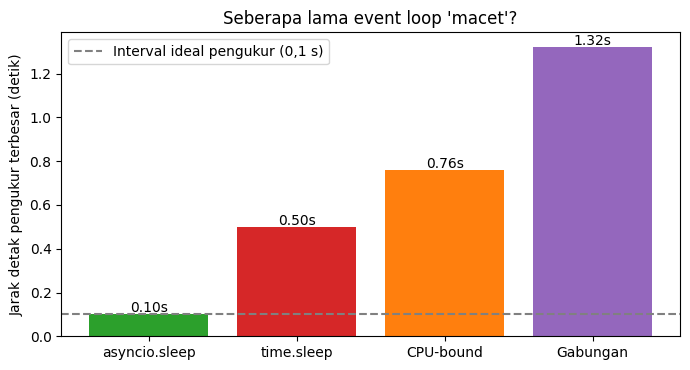

In [9]:
import matplotlib.pyplot as plt

skenario = ["asyncio.sleep", "time.sleep", "CPU-bound", "Gabungan"]
maks_jarak = [max(jarak_async), max(jarak_time), max(jarak_cpu), max(jarak_gabungan)]

plt.figure(figsize=(7, 3.8))
batang = plt.bar(skenario, maks_jarak, color=["tab:green", "tab:red", "tab:orange", "tab:purple"])
plt.axhline(0.1, ls="--", color="gray", label="Interval ideal pengukur (0,1 s)")
for b, v in zip(batang, maks_jarak):
    plt.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.2f}s", ha="center")
plt.ylabel("Jarak detak pengukur terbesar (detik)")
plt.title("Seberapa lama event loop 'macet'?")
plt.legend()
plt.tight_layout()
plt.show()

**Hasil pengamatan:**

| Skenario | Jarak detak pengukur terbesar | Kesimpulan |
|---|---|---|
| `asyncio.sleep(0.5)` | ≈ 0,10 s (6 detak) | Sehat: pengukur tetap berdetak tiap 0,1 s |
| `time.sleep(0.5)` | ≈ 0,50 s (hanya 2 detak) | Pengukur **membeku** selama seluruh durasi sleep |
| Faktorial 60000 (CPU-bound) | ≈ 0,76 s (hanya 2 detak) | Pengukur **membeku** selama seluruh durasi komputasi |
| Ketiganya + pengukur | ≈ 1,3 s | Pengukur membeku selama kedua blocking call dijumlahkan (≈ 0,5 + 0,8) |

**Coroutine mana yang mengganggu pengukur, dan mengapa?**

1. **`tugas_time_sleep` mengganggu.** `time.sleep()` adalah fungsi sinkron: ia menidurkan seluruh *thread*, dan karena asyncio hanya punya satu thread, event loop ikut tertidur. Tidak ada `await`, sehingga tidak ada titik di mana coroutine menyerahkan giliran. Bandingkan dengan `asyncio.sleep()` yang menjadwalkan timer lalu mengembalikan kendali ke event loop.
2. **`tugas_cpu_bound` juga mengganggu**, dengan alasan yang sama (tidak ada `await` sama sekali) tetapi sebabnya berbeda: di sini bukan menunggu, melainkan CPU benar-benar sibuk menghitung. Selama loop berjalan, event loop tidak sempat mengerjakan apa pun. Ini poin penting: asyncio **tidak membantu CPU-bound**, karena konkurensinya hanya terjadi di titik `await`.
3. **`tugas_async_sleep` tidak mengganggu.** Pada uji tunggal, pengukur tetap berdetak normal. Pada uji gabungan ia justru menjadi *korban*: timer 0,5 s-nya sebenarnya sudah jatuh tempo, tetapi ia baru bisa dilanjutkan setelah kedua blocking call selesai. Karena itu urutan selesainya paling akhir, padahal durasinya paling pendek.

Total waktu gabungan (≈ 1,4 s) mendekati penjumlahan kedua blocking call plus sedikit sisa, bukan ≈ 0,8 s seperti yang diharapkan jika semuanya benar-benar konkuren. Ini sesuai pesan di bagian 4 materi: *blocking call akan memblokir seluruh event loop, bukan hanya coroutine yang memanggilnya.*

**Perbaikan:** ganti `time.sleep()` dengan `await asyncio.sleep()`. Untuk pekerjaan CPU-bound, jangan dijalankan langsung di coroutine; lemparkan ke `ProcessPoolExecutor` lewat `run_in_executor()`, atau gunakan `multiprocessing` (Pertemuan 3).

---
## 3️⃣ Producer–Multi-Consumer dengan Prioritas

**Modifikasi dari contoh 6.4:**
- `asyncio.Queue` diganti `asyncio.PriorityQueue`, yang selalu mengeluarkan item dengan nilai **terkecil** terlebih dahulu (angka prioritas lebih kecil = lebih penting).
- Setiap item dimasukkan sebagai tuple `(prioritas, nomor_urut, isi)`. `nomor_urut` berfungsi sebagai *tie-breaker* agar item berprioritas sama tetap keluar sesuai urutan masuk (FIFO), dan agar Python tidak pernah membandingkan elemen `isi` (misalnya `str` dengan `None`).
- Sinyal berhenti (`None`) untuk consumer diberi prioritas **99** (lebih "besar" dari 1–3), sehingga baru diambil setelah semua item nyata habis.
- Agar efek prioritas terlihat, producer dibuat lebih cepat daripada consumer sehingga item menumpuk di antrian.

In [10]:
import asyncio
import random
import time

random.seed(7)  # supaya hasil bisa direproduksi

JUMLAH_CONSUMER = 3
JUMLAH_ITEM = 12
PRIORITAS_SENTINEL = 99
urutan_diambil = []   # log urutan item diambil consumer: (prioritas, nomor_urut, nama_item)

async def producer(queue, jumlah_item):
    for i in range(jumlah_item):
        prioritas = random.randint(1, 3)
        item = f"item-{i}"
        await asyncio.sleep(0.005)                    # producer cepat
        await queue.put((prioritas, i, item))
        print(f"[Producer] menghasilkan: {item} (prioritas {prioritas})")
    for k in range(JUMLAH_CONSUMER):                  # sinyal selesai, prioritas paling rendah
        await queue.put((PRIORITAS_SENTINEL, jumlah_item + k, None))

async def consumer(queue, nama):
    while True:
        prioritas, nomor, item = await queue.get()
        if item is None:
            queue.task_done()
            break
        urutan_diambil.append((prioritas, nomor, item))
        print(f"    [{nama}] mulai memproses {item} (prioritas {prioritas})")
        await asyncio.sleep(random.uniform(0.15, 0.25))   # consumer lambat
        queue.task_done()

queue = asyncio.PriorityQueue(maxsize=20)

await asyncio.gather(
    producer(queue, JUMLAH_ITEM),
    *[consumer(queue, f"Consumer-{i}") for i in range(JUMLAH_CONSUMER)],
)
print("\nSemua item sudah diproduksi dan dikonsumsi.")

[Producer] menghasilkan: item-0 (prioritas 2)
    [Consumer-0] mulai memproses item-0 (prioritas 2)
[Producer] menghasilkan: item-1 (prioritas 1)
    [Consumer-1] mulai memproses item-1 (prioritas 1)
[Producer] menghasilkan: item-2 (prioritas 1)
    [Consumer-2] mulai memproses item-2 (prioritas 1)
[Producer] menghasilkan: item-3 (prioritas 3)
[Producer] menghasilkan: item-4 (prioritas 3)
[Producer] menghasilkan: item-5 (prioritas 1)
[Producer] menghasilkan: item-6 (prioritas 3)
[Producer] menghasilkan: item-7 (prioritas 1)
[Producer] menghasilkan: item-8 (prioritas 1)
[Producer] menghasilkan: item-9 (prioritas 1)
[Producer] menghasilkan: item-10 (prioritas 2)
[Producer] menghasilkan: item-11 (prioritas 2)


    [Consumer-1] mulai memproses item-5 (prioritas 1)
    [Consumer-2] mulai memproses item-7 (prioritas 1)
    [Consumer-0] mulai memproses item-8 (prioritas 1)


    [Consumer-1] mulai memproses item-9 (prioritas 1)
    [Consumer-2] mulai memproses item-10 (prioritas 2)


    [Consumer-0] mulai memproses item-11 (prioritas 2)
    [Consumer-2] mulai memproses item-3 (prioritas 3)


    [Consumer-1] mulai memproses item-4 (prioritas 3)
    [Consumer-0] mulai memproses item-6 (prioritas 3)



Semua item sudah diproduksi dan dikonsumsi.


### Verifikasi urutan prioritas

In [11]:
print("Urutan item diambil consumer:")
for n, (p, no, item) in enumerate(urutan_diambil, 1):
    print(f"  {n:>2}. {item:<8} prioritas {p}")

# Tiga item pertama diambil langsung oleh tiga consumer yang sedang menganggur (belum ada antrian),
# jadi prioritas baru berlaku untuk item yang sudah menumpuk di antrian sesudahnya.
sisa = urutan_diambil[JUMLAH_CONSUMER:]
terurut = sisa == sorted(sisa)
print(f"\nItem setelah {JUMLAH_CONSUMER} item pertama diambil terurut (prioritas, nomor urut)? ->", terurut)
print("Urutan prioritas item tersebut:", [p for p, _, _ in sisa])

Urutan item diambil consumer:
   1. item-0   prioritas 2
   2. item-1   prioritas 1
   3. item-2   prioritas 1
   4. item-5   prioritas 1
   5. item-7   prioritas 1
   6. item-8   prioritas 1
   7. item-9   prioritas 1
   8. item-10  prioritas 2
   9. item-11  prioritas 2
  10. item-3   prioritas 3
  11. item-4   prioritas 3
  12. item-6   prioritas 3

Item setelah 3 item pertama diambil terurut (prioritas, nomor urut)? -> True
Urutan prioritas item tersebut: [1, 1, 1, 1, 2, 2, 3, 3, 3]


**Hasil dan penjelasan:**

- Item yang diambil consumer setelah antrian menumpuk keluar **berurutan menurut prioritas**: `1, 1, 1, 1, 2, 2, 3, 3, 3`, dan verifikasi di sel sebelumnya menghasilkan `True`. Item berprioritas sama keluar sesuai urutan masuknya (mis. `item-5, item-7, item-8, item-9` untuk prioritas 1) berkat `nomor_urut` pada tuple.
- **Tiga item pertama** (`item-0`, `item-1`, `item-2`) diambil langsung sesuai urutan datang, termasuk `item-0` yang berprioritas 2. Penyebabnya, saat itu ketiga consumer sedang menganggur dan antrian masih kosong, sehingga belum ada item lain untuk dibandingkan. `PriorityQueue` hanya mengurutkan item yang **sudah ada di dalam antrian** saat `get()` dipanggil. Prioritas baru terasa ketika producer lebih cepat daripada consumer (backlog terbentuk).
- Prioritas **tidak memotong** pekerjaan yang sedang diproses; ia hanya menentukan siapa yang diambil berikutnya.
- Sinyal berhenti `None` diberi prioritas 99 agar baru diambil setelah semua item nyata habis. Jika sinyal diberi prioritas 1–3, consumer bisa berhenti sebelum antrian kosong.
- Risiko pola ini adalah *starvation*: jika item berprioritas tinggi terus berdatangan, item berprioritas rendah bisa menunggu sangat lama.

---
## 4️⃣ Refleksi Singkat

Untuk kasus I/O-bound seperti memanggil API PyPI, **threading** paling cepat saya pahami: kodenya mirip kode sekuensial biasa, cukup memakai `ThreadPoolExecutor(max_workers=...)`. Harganya adalah kewaspadaan terhadap race condition dan Lock. **multiprocessing** terasa paling berlebihan untuk kasus ini: ada overhead membuat proses dan serialisasi data, padahal bottleneck-nya menunggu jaringan, bukan CPU. **asyncio** awalnya paling membingungkan. Saya sempat mengira `await a(); await b()` sudah konkuren, padahal waktunya sama dengan sekuensial, dan `time.sleep()` di dalam coroutine ternyata membekukan semua coroutine lain (Latihan 2). Namun setelah paham bahwa giliran hanya berpindah di titik `await`, alurnya justru lebih mudah ditebak daripada threading. Kesimpulan saya: threading paling mudah dipahami di awal, tetapi asyncio paling terkontrol dan hemat untuk puluhan hingga ribuan koneksi, asalkan semua library-nya mendukung async.

*(119 kata — dari pengalaman mengerjakan notebook ini dan materi Pertemuan 2, 3, dan 7.)*